# 11 · Idea B — Adjacent carry & B-flip

**Original B:** pre-registered negative。Gross 在扣成本前已经为负，B 作为
strategy 已 closed。

**B-flip:** post-hoc、gross-only 的 **signal research**。它不是原 B 的
rescue，也不进入 cross-idea official net comparison。这里要回答的是：
这个信号里面有多少有效信息、稳不稳定、之后值不值得作为组合的一个
component。

## 1. 约定 / Default-first conventions

- 主结果：D=10 eligible adjacent pairs，两条 leg 都 eligible，
  `min_adv=100`（lagged ADV，取 thinner leg）。
- v2 holdings simulator：USD 10m、equal-notional、weekly event dates、
  `d=10`、k=1。
- **Headline 是 gross**；v2 三层成本只作为 secondary diagnostic。
- 这是 post-hoc sign flip；2016–2026 只是 stability slice，不是 OOS。
- 第一遍只用 default，**不做 k / D / ADV grid**；候选调参方向放在最后。

In [1]:
import logging
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import b_flip, config, figures as F, horizon, plotstyle as ps, report, v2_rerun, v2_signals

logging.getLogger("fontTools").setLevel(logging.ERROR)
ps.use()
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
OUT = config.OUTPUT_DIR / "b_flip"
OUT.mkdir(parents=True, exist_ok=True)
ROOT_ORDER = (
    rank[["root", "sector"]]
    .drop_duplicates()
    .sort_values(["sector", "root"])["root"]
    .tolist()
)
rank.shape

(1013664, 23)

## 2. B-flip 的定义

每个 date/root，对 M1-M2、M2-M3、M3-M4 三个 adjacent spread 算年化 carry：

`carry_ann = (P_near − P_far) / P_far × 365 / days`

**B-flip = long carry 最低的 adjacent spread（+1 near, −1 far），
short carry 最高的（−1 near, +1 far）。** 共享 leg 自动 net；weekly
rebalance；每个 active root 等预算。

原 B 是 long 最高 carry / short 最低；B-flip 是它的精确反号，但这里用
D=10 eligible universe，所以不是原 B raw universe 的机械负数。

In [2]:
inputs = v2_signals.load_v2_inputs(rank, d=5, k=5, min_adv=100)
flip = b_flip.run_b_flip(inputs, rank)
static = b_flip.run_b_static(inputs, rank)
original = v2_rerun.run_strategy("b", rank, inputs=inputs)
raw_flip = b_flip.run_raw_flip(inputs, original["legs"])

display(flip["performance"].round(3))
print(
    "B-flip full-sample gross Sharpe: "
    f"{report.overall_sharpe(flip['result'], 'ret_gross'):+.3f}"
)

layer  ann_ret_pct  ann_vol_pct  sharpe    t_nw  \
period                                                                        
full            0           gross        0.499        0.469   1.064   7.143   
                1   - half-spread       -0.340        0.482  -0.705  -4.790   
                2          - fees       -0.527        0.489  -1.078  -7.337   
                3  - impact (all)       -2.028        0.599  -3.385 -22.697   
train 1986-2015 0           gross        0.524        0.508   1.031   6.049   
                1   - half-spread       -0.478        0.524  -0.913  -5.428   
                2          - fees       -0.695        0.531  -1.309  -7.806   
                3  - impact (all)       -2.600        0.662  -3.929 -23.524   
test 2016-2026  0           gross        0.429        0.338   1.270   3.962   
                1   - half-spread        0.042        0.342   0.123   0.386   
                2          - fees       -0.060        0.343  -0.176  -0.556   
                3  - impact (all)       -0.441        0.356  -1.240  -3.977   

                   max_dd_pct  turnover_x  cost_bps_yr  
period                                                  
full            0      -0.770      31.398        0.000  
                1     -14.931      31.398       83.887  
                2     -22.403      31.398      102.536  
                3     -84.703      31.398      252.627  
train 1986-2015 0      -0.730      32.319        0.000  
                1     -14.863      32.319      100.176  
                2     -21.407      32.319      121.868  
                3     -79.686      32.319      312.379  
test 2016-2026  0      -0.770      28.846        0.000  
                1      -1.801      28.846       38.743  
                2      -2.242      28.846       48.961  
                3      -5.044      28.846       87.035

B-flip full-sample gross Sharpe: +1.064


### Headline reading

- **D=10 + min_adv=100 主结果**：gross 约 +0.50%/年，vol 0.47%，
  gross Sharpe 约 1.06，t 约 7.1，turnover 约 31×/年。
- **Raw exact flip**（原 B 的精确反号，raw universe）：约 +1.13%/年，
  Sharpe 约 1.26；它包含不可交易的 near-expiry pair，只做 reference。
- **Static front/back**（D=10）：约 +0.11%/年，Sharpe 约 0.21；说明
  期限结构本身贡献很小，信息主要来自 carry ranking。
- Half-spread 一层就把 gross 拖到约 −0.34%/年，all-in 约 −2.0%/年。
  所以这是 **gross signal**，不是 standalone 可交易策略。

,strategy,ann_ret_pct,ann_vol_pct,sharpe,t_nw,max_dd_pct,turnover_x
0,"B-flip (D=10, min_adv=100)",0.499,0.469,1.064,7.143,-0.770,31.398
1,Raw exact flip,1.131,0.895,1.263,9.521,-2.753,31.017
2,Static front/back (D=10),0.108,0.516,0.208,1.559,-5.337,18.226


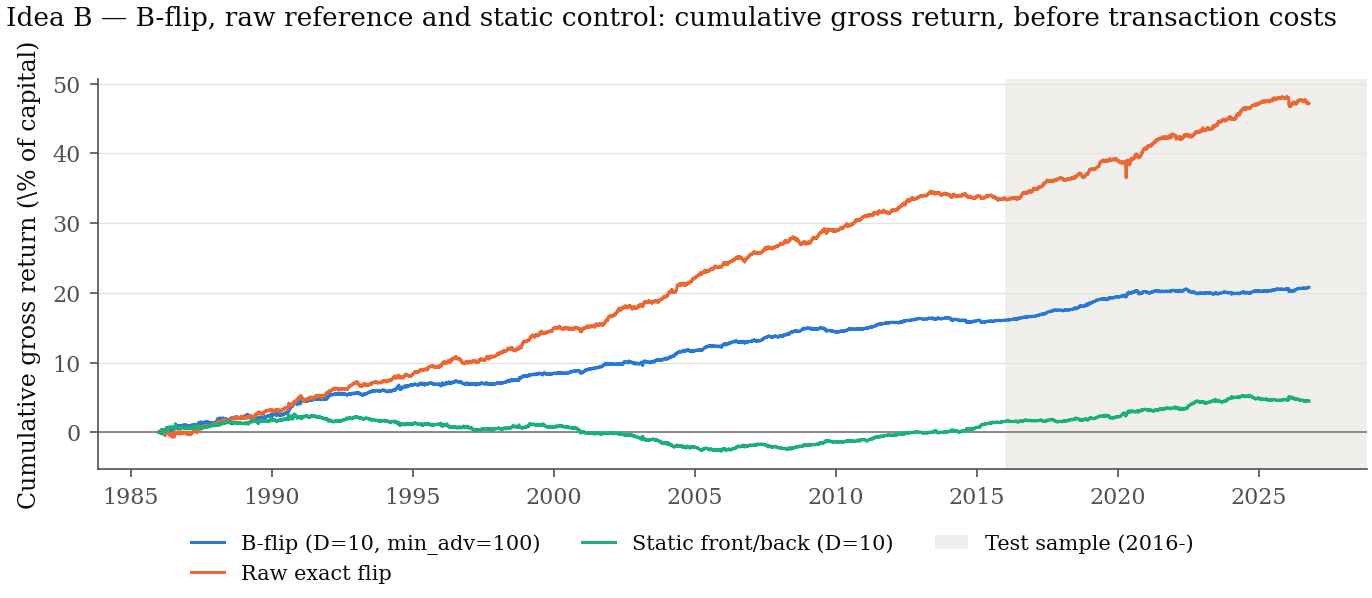

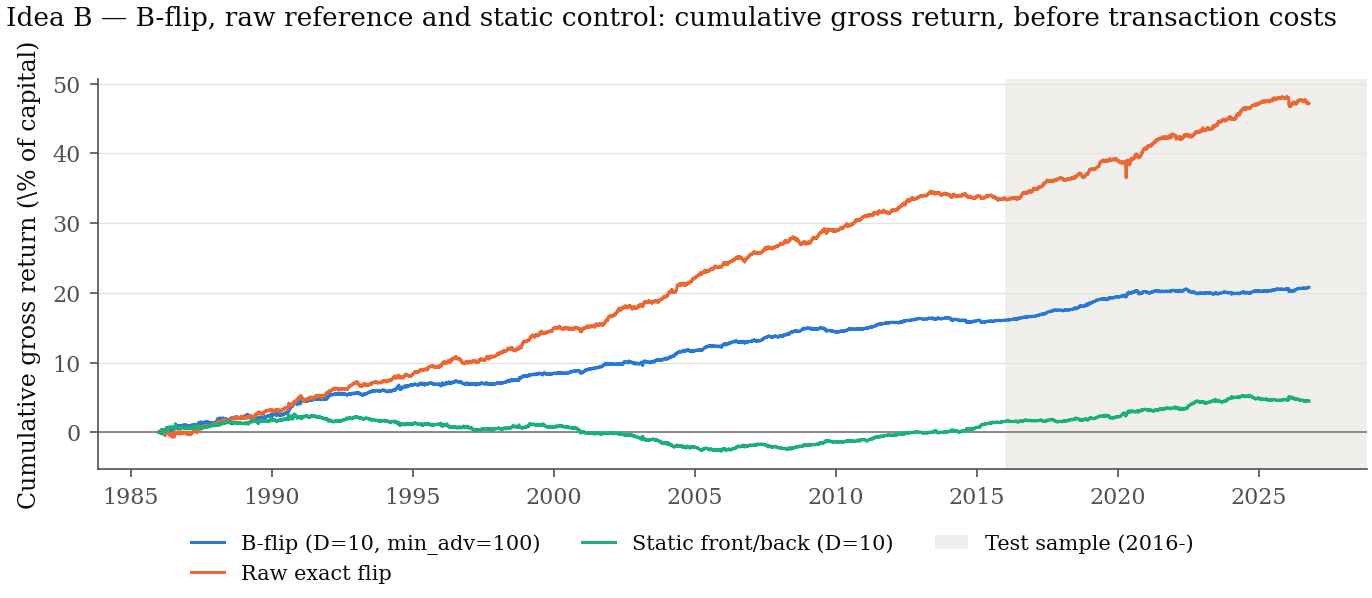

In [3]:
rows = []
for name, item in [
    ("B-flip (D=10, min_adv=100)", flip),
    ("Raw exact flip", raw_flip),
    ("Static front/back (D=10)", static),
]:
    p = item["performance"].xs("full", level="period").set_index("layer").loc["gross"]
    rows.append(dict(strategy=name, **{
        key: p[key] for key in
        ["ann_ret_pct", "ann_vol_pct", "sharpe", "t_nw", "max_dd_pct", "turnover_x"]
    }))
display(pd.DataFrame(rows).round(3))

series = {
    "B-flip (D=10, min_adv=100)": flip["result"].daily.set_index("date")["ret_gross"],
    "Raw exact flip": raw_flip["result"].daily.set_index("date")["ret_gross"],
    "Static front/back (D=10)": static["result"].daily.set_index("date")["ret_gross"],
}
fig = F.nav_compare(series, "Idea B — B-flip, raw reference and static control")
ps.save(fig, "idea_b_flip_nav")
display(fig)

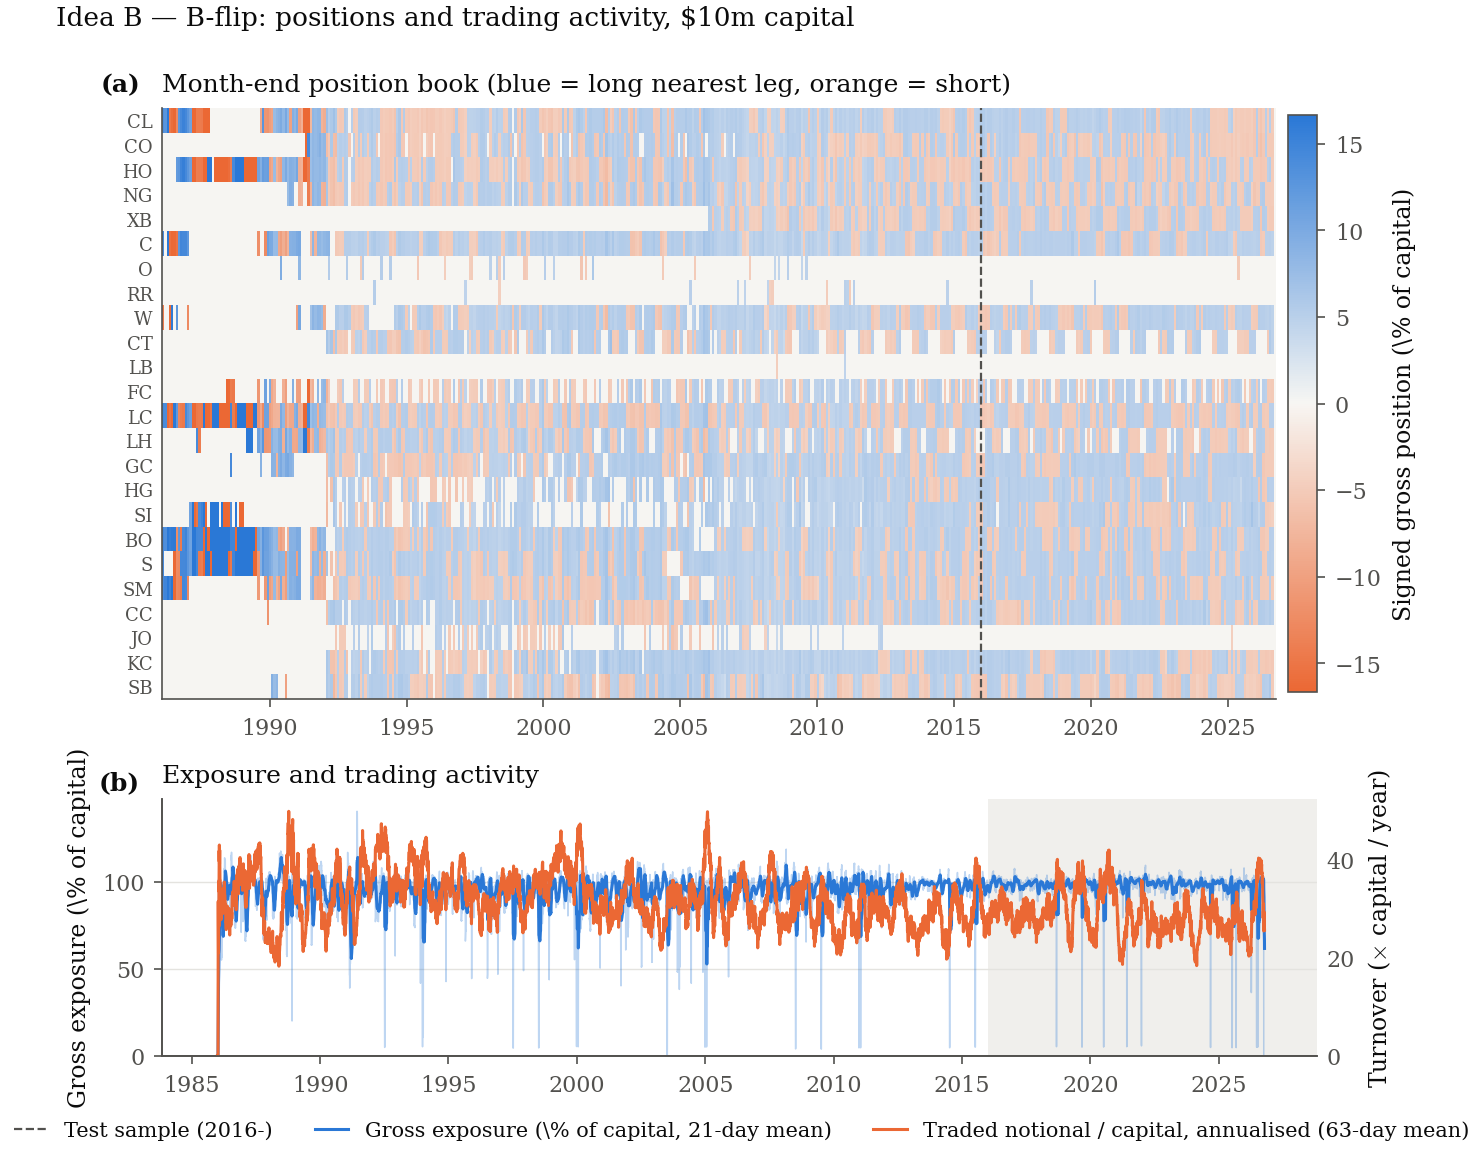

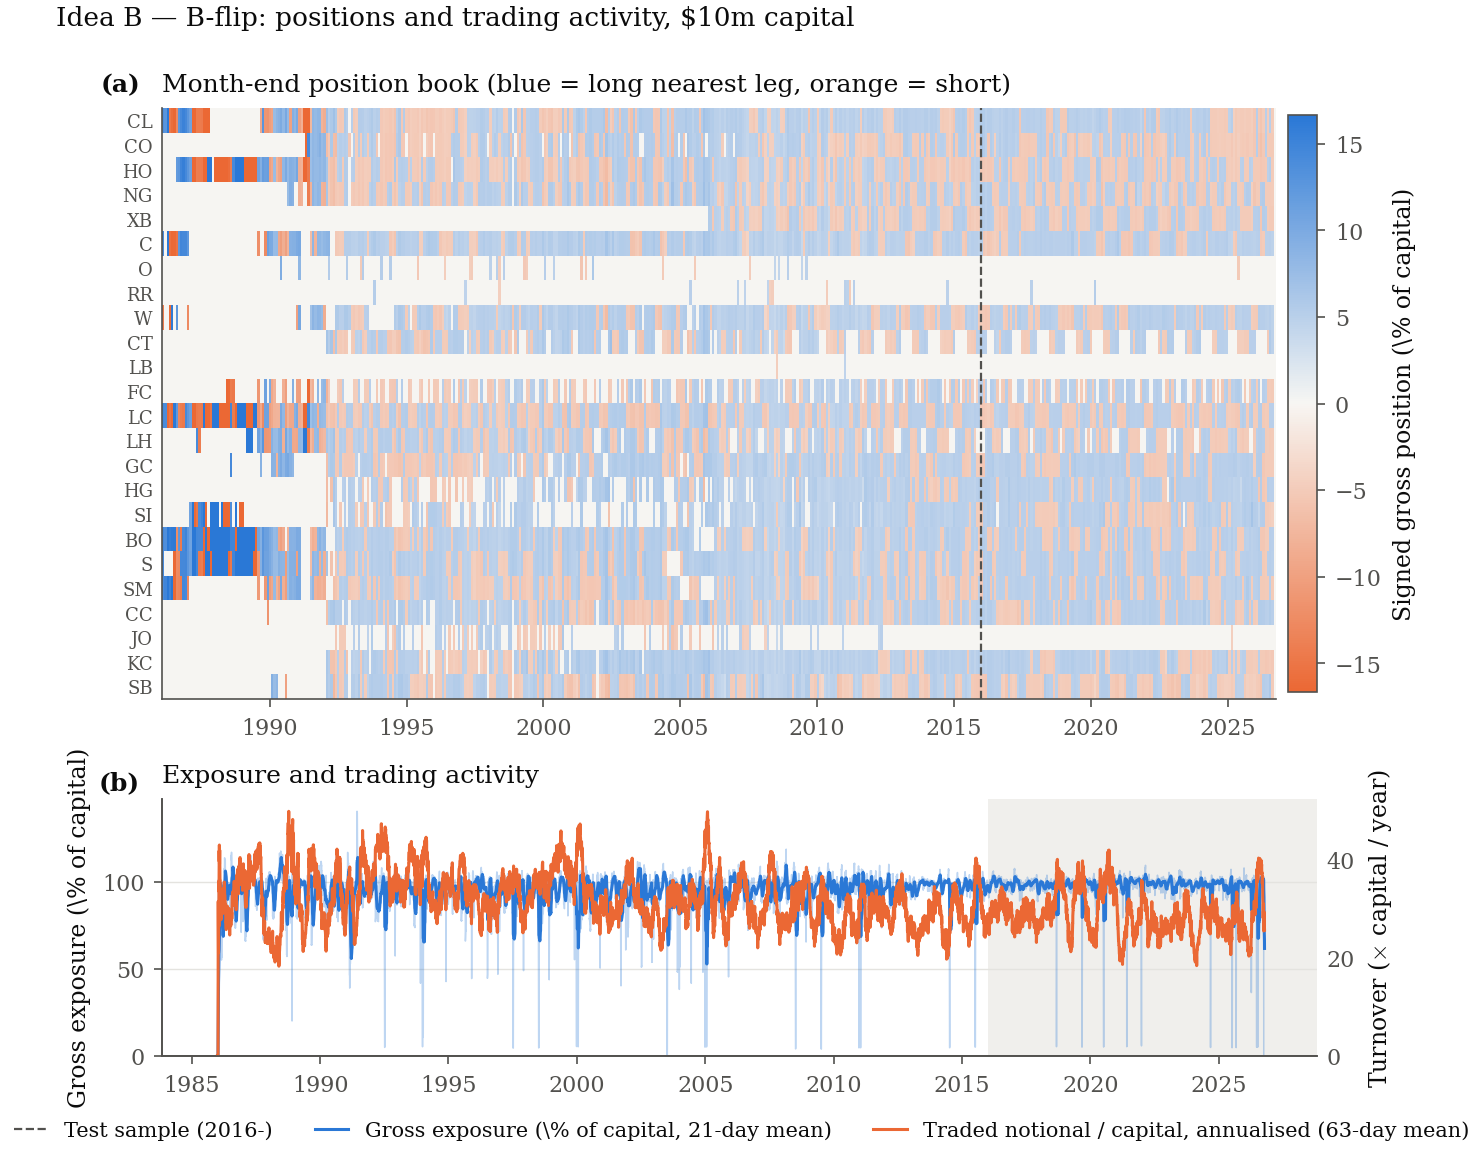

In [4]:
position_panel = F.position_panel(flip["result"], root_order=ROOT_ORDER)
position_panel.to_csv(OUT / "b_flip_positions_month_end.csv")
fig = F.positions(flip["result"], "Idea B — B-flip", root_order=ROOT_ORDER)
ps.save(fig, "idea_b_flip_positions")
display(fig)

## 3. 信息是真的吗？ / Is the information real?

四个检查：timing、horizon、static control、random-ranking placebo。

- **Timing**：`[t, t+1]` 是 same-settle（不可交易）；`[t+1, t+2]` 才是我
  们能拿到的第一天。
- **Horizon**：信号能活多少天；如果只有一天，后面就没有组合价值。
- **Static control**：如果只要 long 近月 / short 远月就能赚，carry 排序
  本身就没有信息。
- **Placebo**：在每个 root-date 内随机打乱 carry 排序，保持 pair 数、
  leg 数和窗口不变；真实排序应该显著好于随机。

,horizon,days,mean_bps,bps_per_day,t_nw,hit_rate,n_dates
0,t+0->t+1,1,2.586,2.586,21.332,0.588,10472
1,t+1->t+2,1,1.176,1.176,9.836,0.541,10472
2,t+2->t+3,1,0.785,0.785,6.630,0.527,10472
3,t+1->t+6,5,3.976,0.795,9.582,0.571,10472


,horizon,days,mean_bps,bps_per_day,t_nw,hit_rate,n_dates
0,t+1->t+2,1,1.176,1.176,9.836,0.541,10472
4,t+1->t+6,5,3.976,0.795,9.582,0.571,10472
9,t+1->t+11,10,6.909,0.691,8.839,0.598,10472
19,t+1->t+21,20,12.408,0.620,8.607,0.616,10377


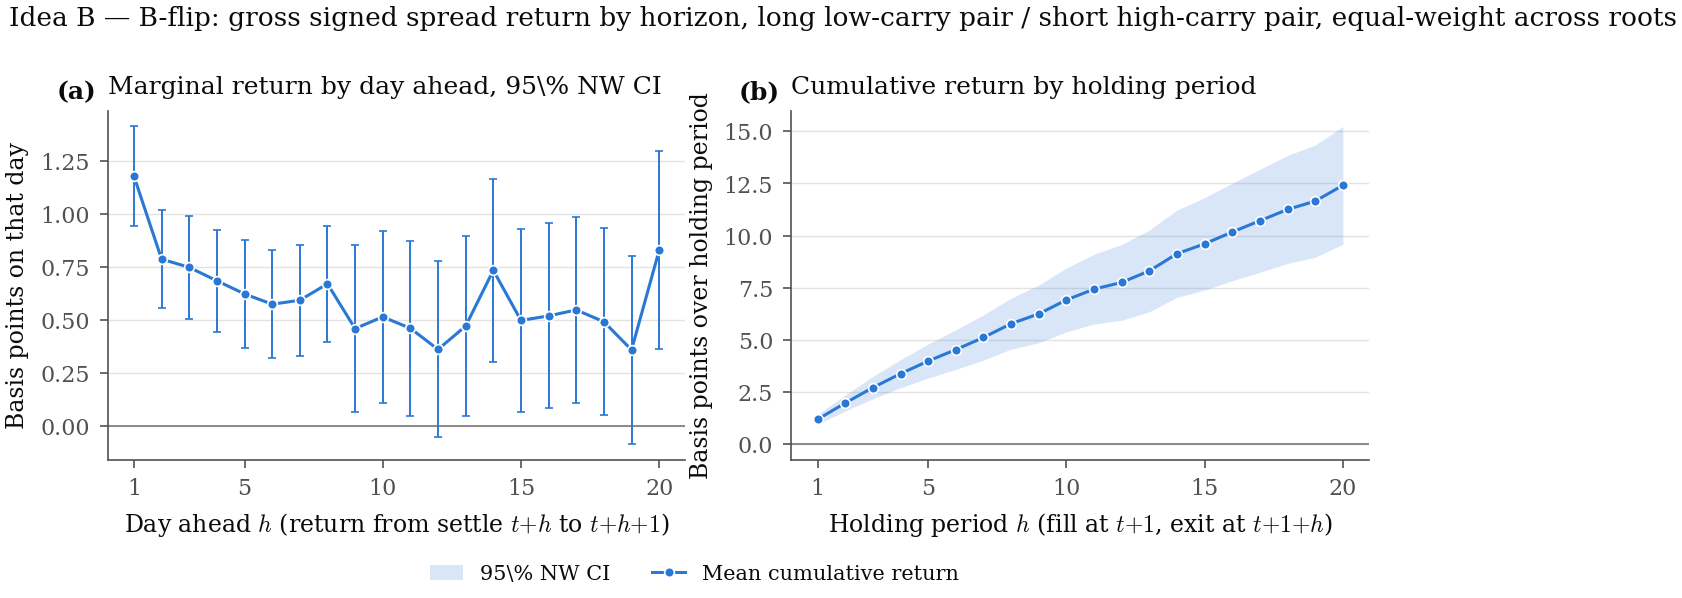

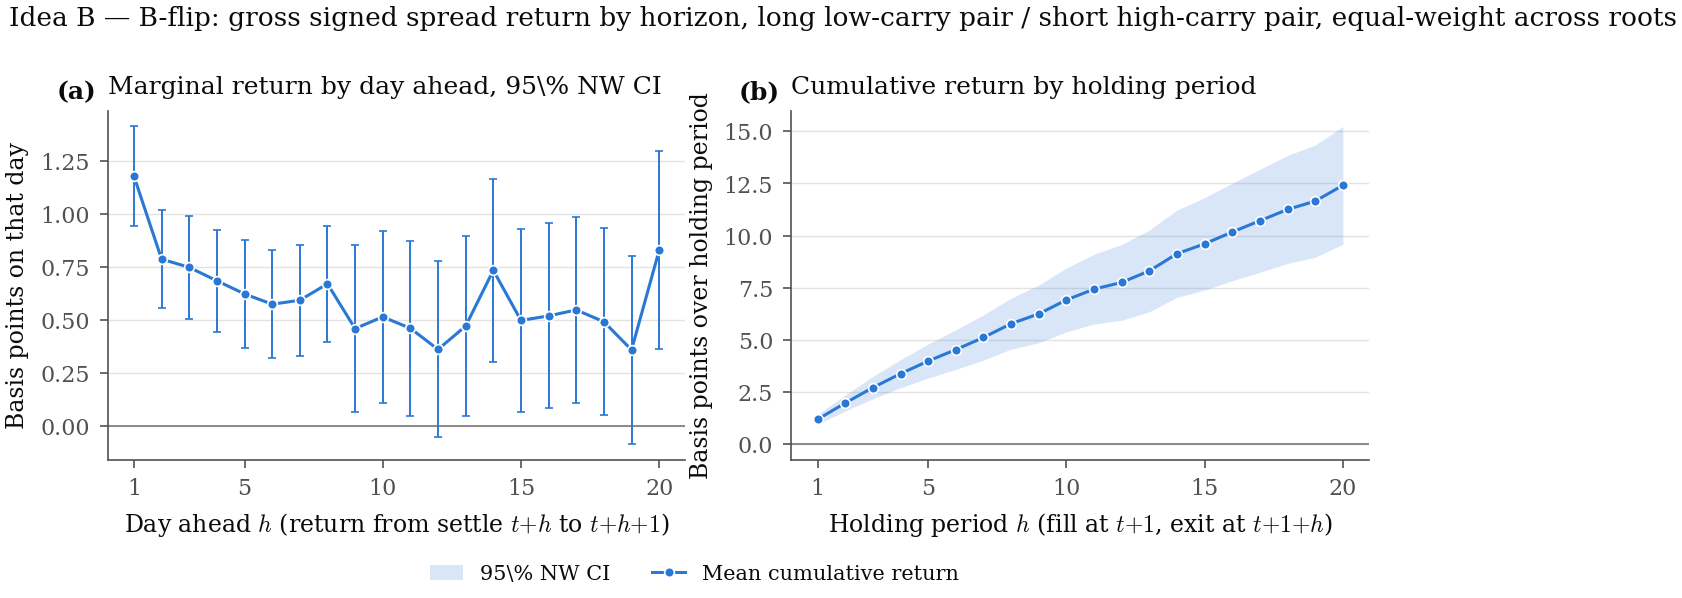

In [5]:
prof = b_flip.horizon_profiles(
    inputs, rank, d=10, min_adv=100,
    marginal=horizon.marginal_horizons(20),
    cumulative=horizon.cumulative_horizons(20),
    timing=[(0, 1), (1, 2), (2, 3), (1, 6)],
)
display(prof["timing"].round(3))
display(prof["cumulative"].iloc[[0, 4, 9, 19]].round(3))
fig = F.horizon_decay(
    prof["marginal"], prof["cumulative"], "Idea B — B-flip",
    formula="long low-carry pair / short high-carry pair, equal-weight across roots",
)
ps.save(fig, "idea_b_flip_horizon")
display(fig)

In [6]:
overlay = (
    flip["result"].daily.set_index("date")["ret_gross"]
    - static["result"].daily.set_index("date")["ret_gross"]
).dropna()
display(pd.DataFrame({
    "mean_ann_pct": [overlay.mean() * 252 * 100],
    "vol_ann_pct": [overlay.std() * np.sqrt(252) * 100],
    "sharpe": [overlay.mean() / overlay.std() * np.sqrt(252)],
    "t_nw": [horizon.newey_west_t(overlay, 5)],
}).round(3))

,mean_ann_pct,vol_ann_pct,sharpe,t_nw
0,0.391,0.698,0.56,3.822


{'actual': np.float64(3.9710272876899966), 'p_one_sided': 0.0, 'p_two_sided': 0.0, 'percentile': 100.0, 'n_boot': 2000, 'n_groups': 179058, 'n_dates': 10472}


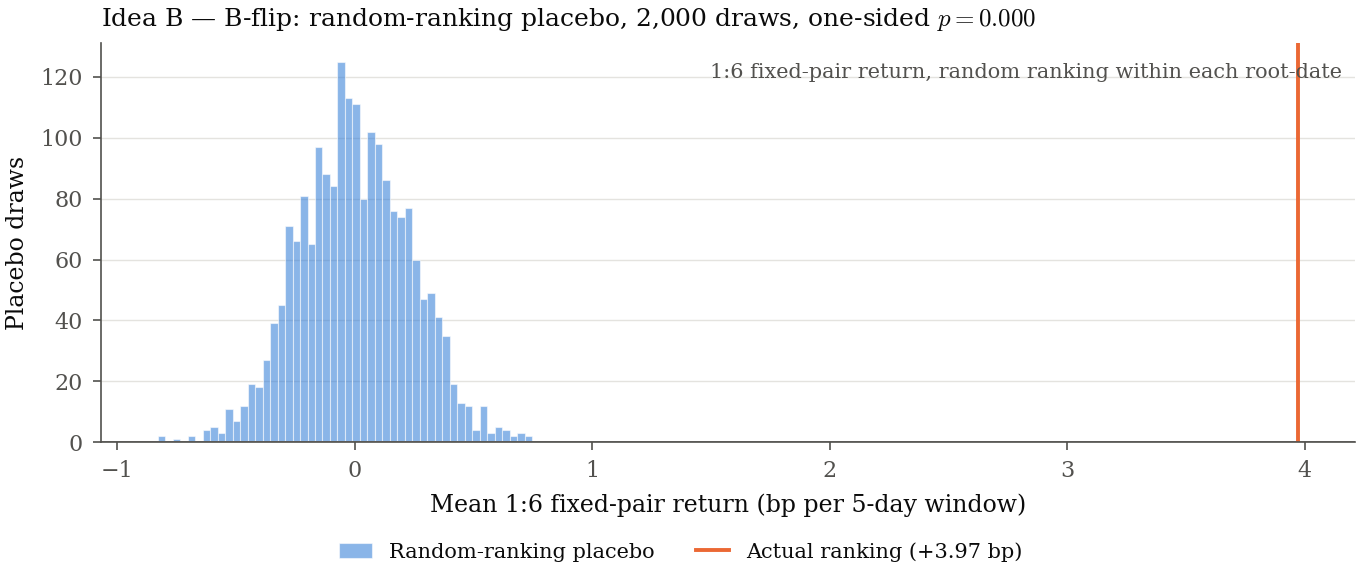

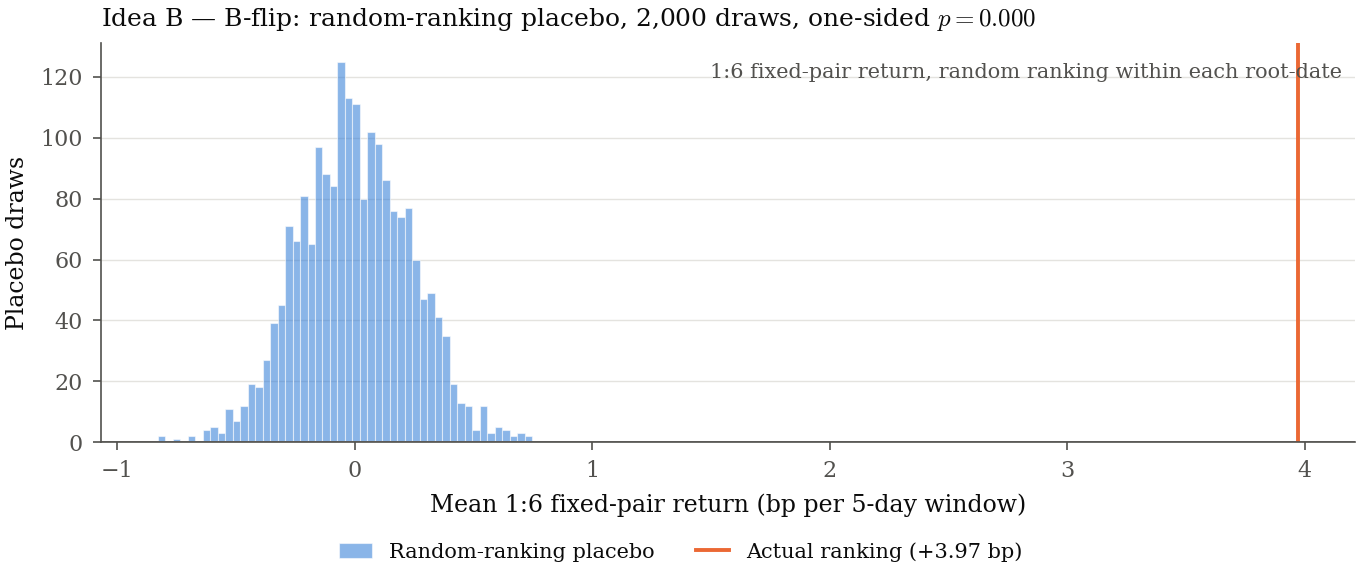

In [7]:
placebo = b_flip.rank_placebo(
    inputs, rank, d=10, min_adv=100, window=(1, 6), n_boot=2000, seed=0
)
print({key: placebo[key] for key in
       ["actual", "p_one_sided", "p_two_sided", "percentile", "n_boot", "n_groups", "n_dates"]})
fig = F.placebo_distribution(
    placebo["draws"], placebo["actual"], "Idea B — B-flip",
    "1:6 fixed-pair return, random ranking within each root-date",
    p_value=placebo["p_one_sided"], n_boot=placebo["n_boot"],
)
ps.save(fig, "idea_b_flip_placebo")
display(fig)

## 4. 信息稳定吗？ / Is it stable?

- **Per-root block bootstrap**：每个 root 自己的 1:6 信号收益，按 21 天块
  重采样 2,000 次，看 mean bps 和 95% CI。这里用 signal-level return，
  不是 v2 的资金分配 contribution。
- **年度 / rolling**：每年是否为正，rolling 3 年 Sharpe 的分布。
- **Root jackknife**：逐个 drop root，看 aggregate 是否依赖某一个品种。

,root,mean_bps,ci_lo_bps,ci_hi_bps,p_value
10,JO,10.192,0.657,18.794,0.036
15,NG,10.086,3.373,16.673,0.001
5,CT,9.534,4.954,14.394,0.001
14,LH,8.975,1.847,16.242,0.016
2,CC,8.404,5.017,11.931,0.000
6,FC,7.773,5.593,9.938,0.000
22,W,6.285,2.862,9.333,0.001
17,RR,6.282,-10.846,25.083,0.448
11,KC,5.923,3.390,8.787,0.000
16,O,4.086,-7.579,21.119,0.371


positive mean: 22/24; positive 95% CI: 17/24


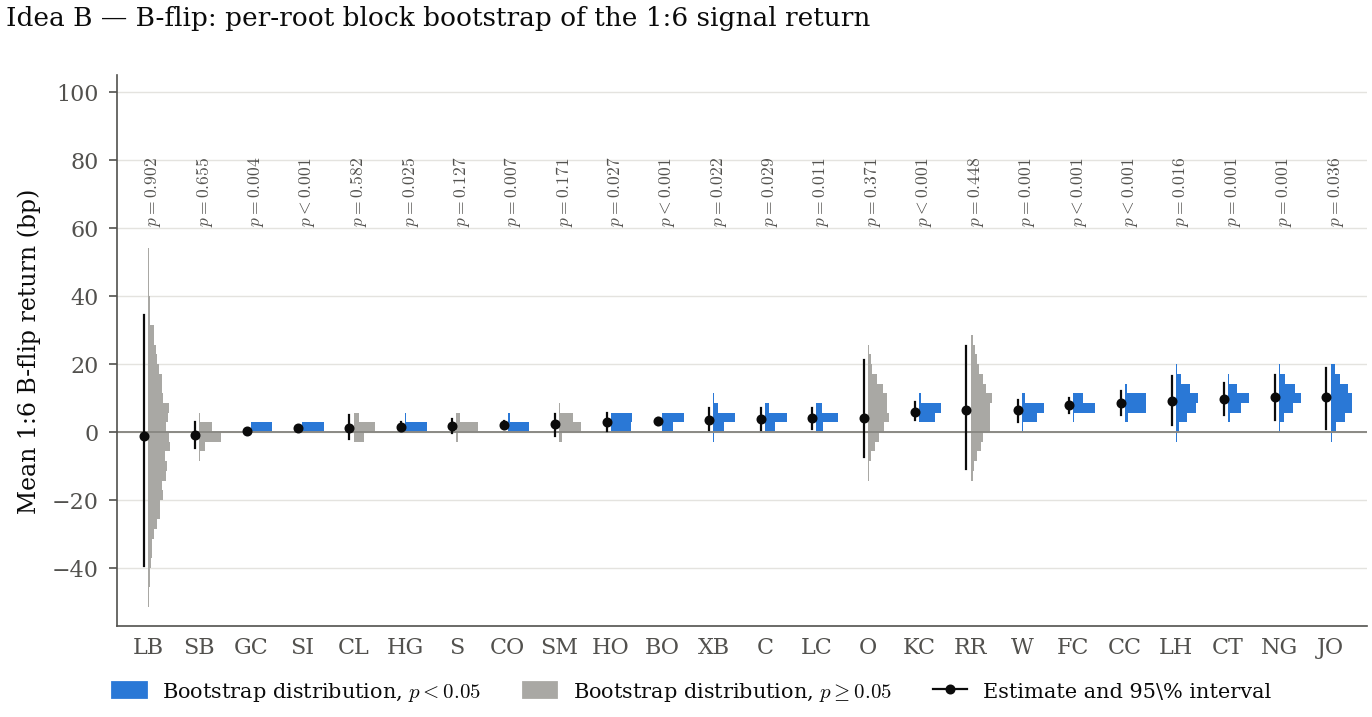

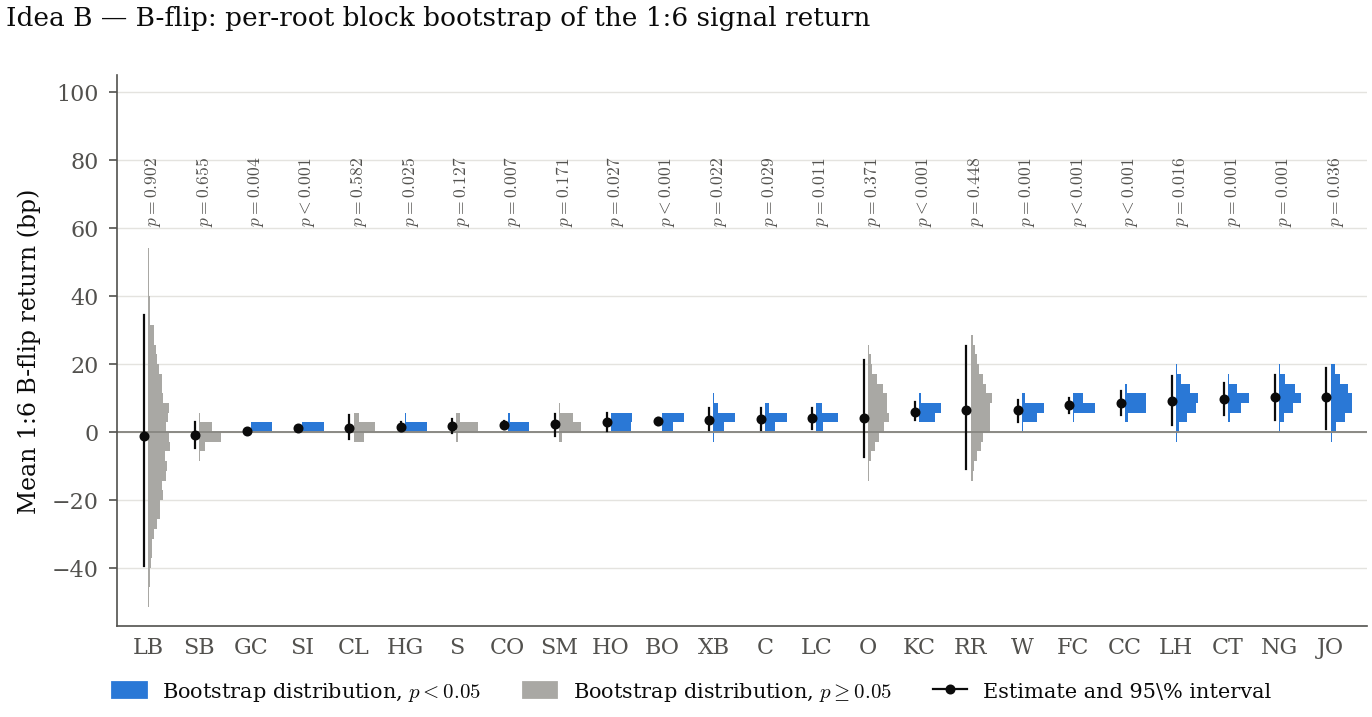

In [8]:
boot, draws = b_flip.bootstrap_selected(
    prof["selected"], window=(1, 6), block=21, n_boot=2000, seed=0
)
display(
    boot.sort_values("mean_bps", ascending=False)
    [["root", "mean_bps", "ci_lo_bps", "ci_hi_bps", "p_value"]]
    .round(3)
)
print(
    f"positive mean: {(boot['mean_bps'] > 0).sum()}/{len(boot)}; "
    f"positive 95% CI: {(boot['ci_lo_bps'] > 0).sum()}/{len(boot)}"
)
fig = F.bootstrap_distribution(
    boot, draws, "mean_bps", "Mean 1:6 B-flip return (bp)",
    "Idea B — B-flip: per-root block bootstrap of the 1:6 signal return",
    test=True,
)
ps.save(fig, "idea_b_flip_bootstrap")
display(fig)

In [9]:
daily = flip["result"].daily.set_index("date")["ret_gross"]
annual = daily.groupby(daily.index.year).sum() * 100
monthly = daily.groupby(daily.index.to_period("M")).sum()
rolling = daily.rolling(756).apply(
    lambda x: x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else np.nan
)
display(pd.DataFrame({
    "positive years": [f"{int((annual > 0).sum())}/{len(annual)}"],
    "worst year (%)": [annual.min()],
    "best year (%)": [annual.max()],
    "positive months": [f"{int((monthly > 0).sum())}/{len(monthly)}"],
    "rolling 3y Sharpe min": [rolling.min()],
    "median": [rolling.median()],
    "max": [rolling.max()],
    "positive rolling windows": [f"{(rolling > 0).mean():.1%}"],
}).round(3))

jak = b_flip.root_jackknife(flip["result"], 10_000_000.0)
display(jak.sort_values("ann_ret_pct").head(5).round(3))
display(jak.sort_values("ann_ret_pct").tail(5).round(3))

,positive years,worst year (%),best year (%),positive months,rolling 3y Sharpe min,median,max,positive rolling windows
0,37/41,-0.554,1.879,321/490,-0.444,1.146,3.225,85.4%


,root,ann_ret_pct,sharpe,t_nw
16,NG,0.439,1.007,6.868
3,CC,0.443,0.961,6.430
15,LH,0.447,1.027,6.886
10,HO,0.453,1.033,7.043
7,FC,0.464,0.997,6.705


,root,ann_ret_pct,sharpe,t_nw
13,LB,0.498,1.064,7.129
18,RR,0.498,1.065,7.157
8,GC,0.499,1.063,7.132
0,ALL,0.499,1.064,7.143
20,SB,0.504,1.088,7.335


## 5. 能落地吗？ / Default implementation profile

这一节只看 default 的 turnover、成本层、capacity 和 $1m 整手，不做 k 或
ADV 的 grid；这些放到最后作为候选方向。

,ann_ret_pct,ann_vol_pct,sharpe,turnover_x,cost_bps_yr
layer,,,,,
gross,0.499,0.469,1.064,31.398,0.000
- half-spread,-0.340,0.482,-0.705,31.398,83.887
- fees,-0.527,0.489,-1.078,31.398,102.536
- impact (all),-2.028,0.599,-3.385,31.398,252.627


,capital,gross_bps_yr,half_spread_bps_yr,fee_bps_yr,impact_bps_yr,ann_ret_pct,sharpe
0,100000.0,49.854,83.887,18.65,0.118,-0.528,-1.081
1,300000.0,49.854,83.887,18.65,2.544,-0.552,-1.127
2,1000000.0,49.854,83.887,18.65,19.520,-0.722,-1.442
3,3000000.0,49.854,83.887,18.65,62.963,-1.156,-2.187
4,10000000.0,49.854,83.887,18.65,150.091,-2.028,-3.385


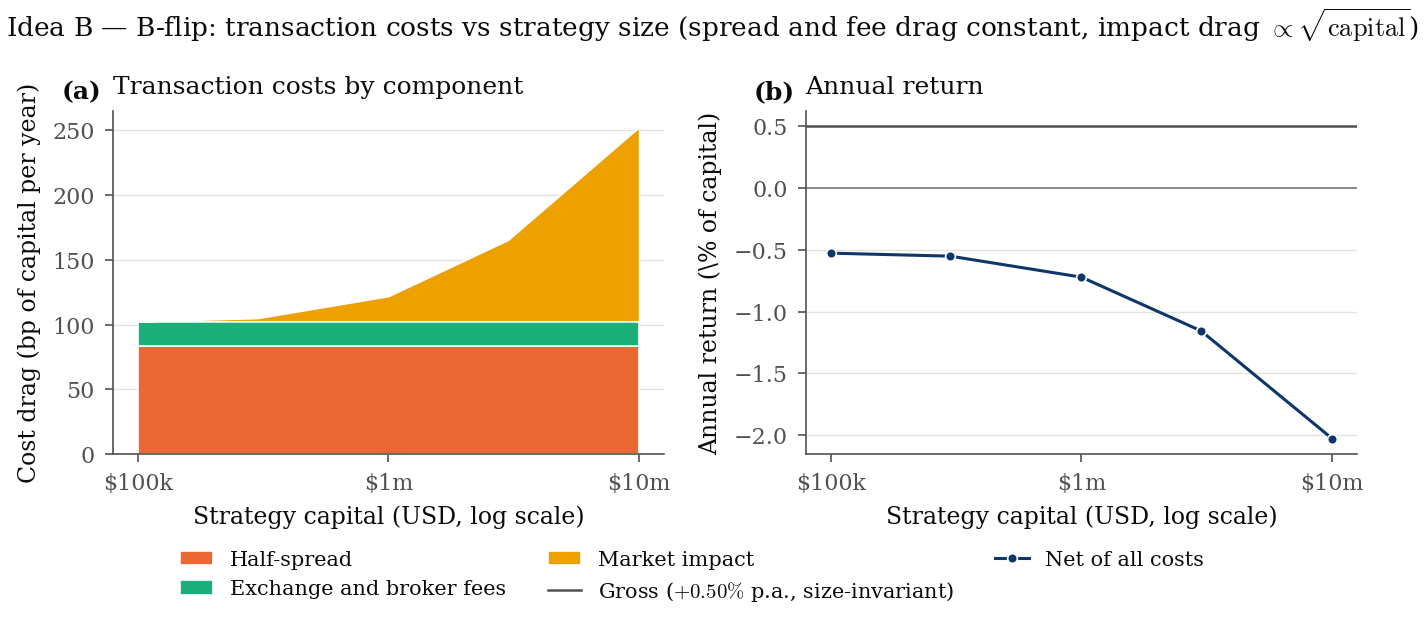

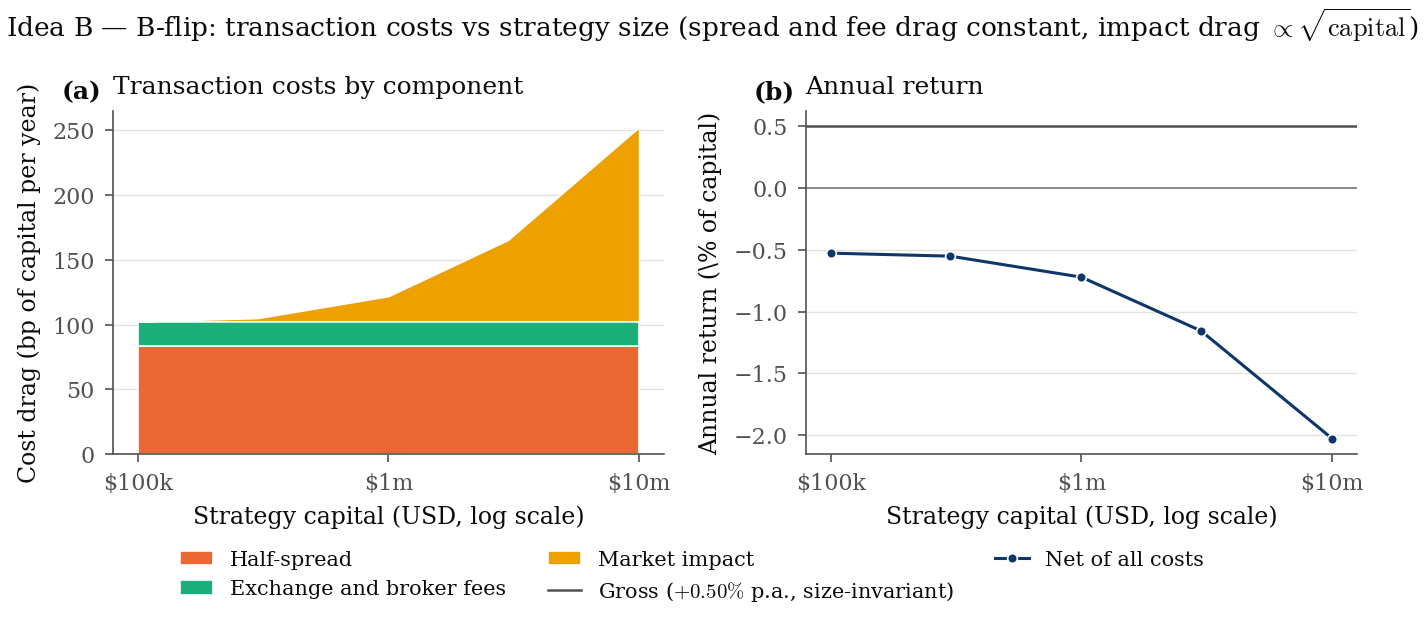

In [10]:
full = flip["performance"].xs("full", level="period").set_index("layer")
display(
    full[["ann_ret_pct", "ann_vol_pct", "sharpe", "turnover_x", "cost_bps_yr"]]
    .round(3)
)
cap = report.capacity_curve(
    flip["result"], capitals=[1e5, 3e5, 1e6, 3e6, 1e7]
)
display(cap.round(3))
fig = F.capacity(cap, "Idea B — B-flip")
ps.save(fig, "idea_b_flip_capacity")
display(fig)

In [11]:
lot = b_flip.run_b_flip(
    inputs, rank, capital=1_000_000.0, round_lots=True
)
held = lot["result"].by_root.loc[lot["result"].by_root["gross_notional"] > 0]
print(
    f"$1m whole lots: {len(held):,} root-days held, "
    f"{held['root'].nunique()} roots ever held"
)
display(
    lot["performance"].xs("full", level="period").set_index("layer")
    [["ann_ret_pct", "sharpe", "turnover_x"]]
    .round(3)
)

$1m whole lots: 67,980 root-days held, 24 roots ever held


,ann_ret_pct,sharpe,turnover_x
layer,,,
gross,0.276,0.285,16.718
- half-spread,-0.377,-0.385,16.718
- fees,-0.522,-0.533,16.718
- impact (all),-0.738,-0.749,16.718


## 6. Original B：pre-registered negative，closed

原 B 的结果保留在这里，不因为 B-flip 而改写。它是 pre-registered 的
negative：扣成本前 gross 已经为负，成本让它更差。B-flip 是之后提出的
新 hypothesis，不是 rescue。

layer  ann_ret_pct  ann_vol_pct  sharpe    t_nw  \
period                                                                        
full            0           gross       -1.131        0.895  -1.263  -9.521   
                1   - half-spread       -2.180        0.904  -2.410 -18.017   
                2          - fees       -2.374        0.908  -2.616 -19.519   
                3  - impact (all)       -4.469        0.988  -4.525 -32.954   
train 1986-2015 0           gross       -1.095        0.753  -1.454  -8.486   
                1   - half-spread       -2.302        0.768  -2.999 -17.419   
                2          - fees       -2.523        0.773  -3.265 -18.961   
                3  - impact (all)       -4.767        0.881  -5.412 -31.277   
test 2016-2026  0           gross       -1.229        1.204  -1.020  -4.558   
                1   - half-spread       -1.840        1.204  -1.528  -6.777   
                2          - fees       -1.961        1.205  -1.628  -7.211   
                3  - impact (all)       -3.643        1.235  -2.950 -12.784   

                   max_dd_pct  turnover_x  cost_bps_yr  
period                                                  
full            0     -48.872      31.017        0.000  
                1     -91.638      31.017      104.890  
                2     -99.608      31.017      124.358  
                3    -186.717      31.017      333.822  
train 1986-2015 0     -35.283      31.438        0.000  
                1     -70.736      31.438      120.681  
                2     -77.376      31.438      142.796  
                3    -146.050      31.438      367.146  
test 2016-2026  0     -14.839      29.848        0.000  
                1     -21.158      29.848       61.128  
                2     -22.408      29.848       73.260  
                3     -40.797      29.848      241.469

Original B full-sample all-in net Sharpe: -4.525


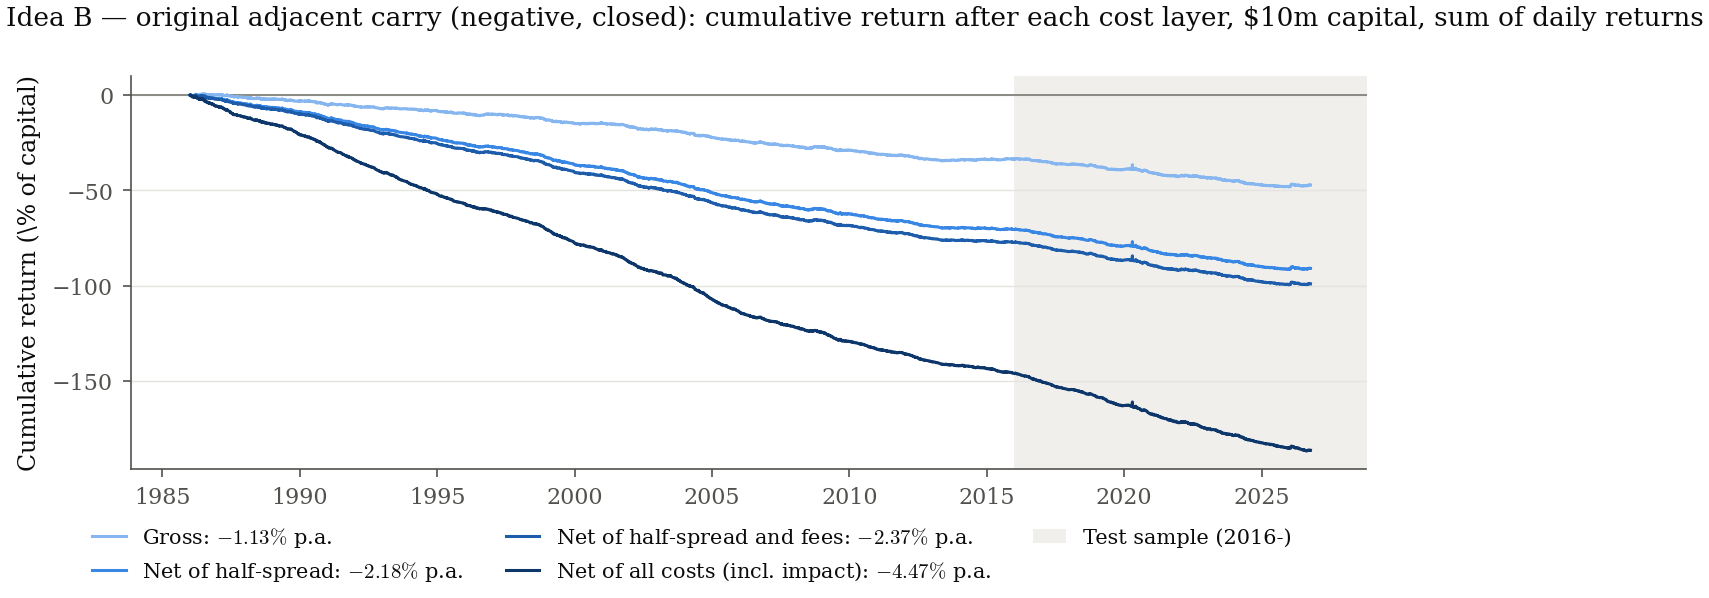

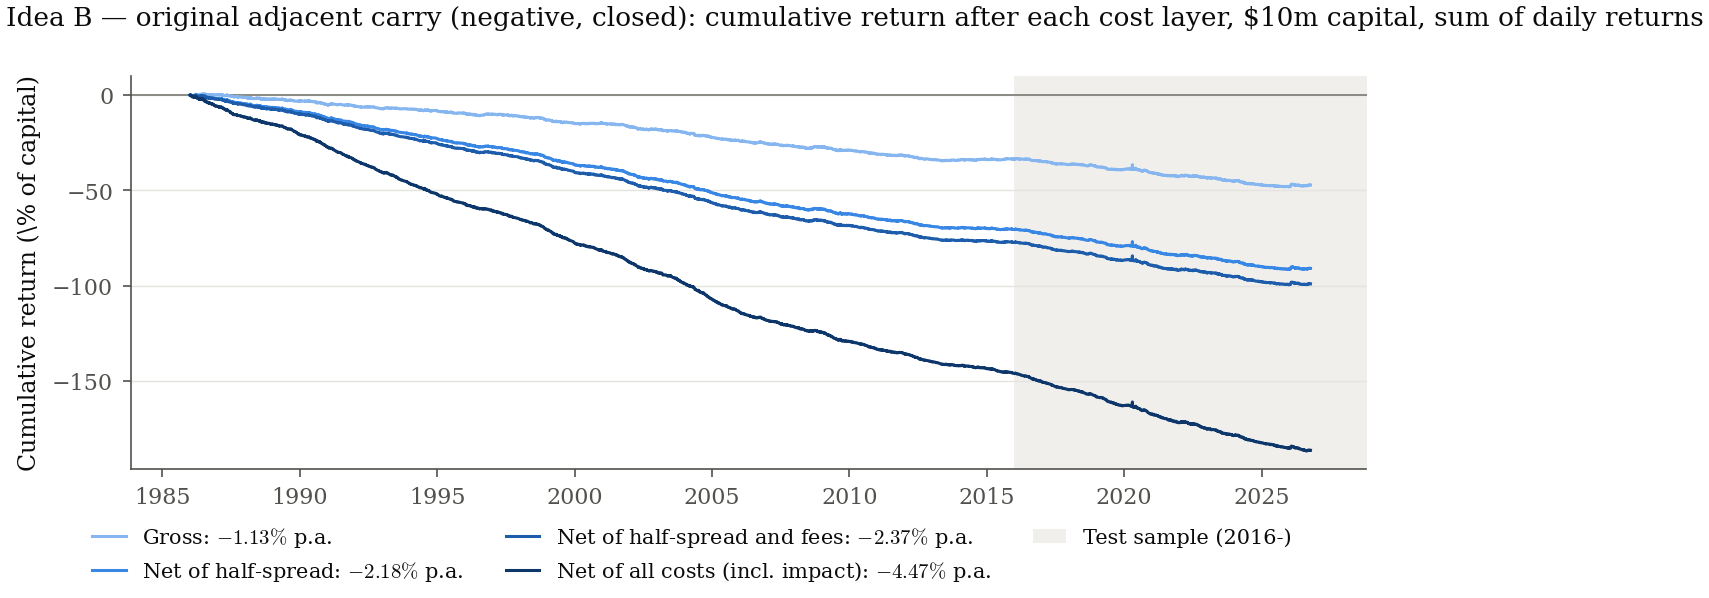

In [12]:
display(original["performance"].round(3))
print(
    "Original B full-sample all-in net Sharpe: "
    f"{report.overall_sharpe(original['result']):+.3f}"
)
fig = F.nav_by_cost_layer(
    original["result"],
    "Idea B — original adjacent carry (negative, closed)",
)
ps.save(fig, "idea_b_original_pnl")
display(fig)

## 7. 读这个结果 / Reading

**B-flip 是 within-curve carry reversal，不是原 B 的 carry continuation。**
它 long 最低 carry 的 adjacent spread，short 最高 carry 的；本质上是在
赌曲线最极端的 carry 点反转。

**有效信息**

- Default（D=10 + min_adv=100）：gross 约 +0.50%/年，Sharpe 约 1.06，
  t 约 7.1；raw exact flip 约 +1.13%/年、Sharpe 约 1.26。
- Signal level：1:6 约 +3.98 bps（t 约 9.6），1:21 约 +12.4 bps
  （t 约 8.6）；same-settle 的 `[t, t+1]` 更大，但不可交易。
- Static front/back 只有约 +0.11%/年、Sharpe 0.21；carry ranking 的
  overlay 明显更大。
- Placebo：真实排序的 1:6 mean 约 +3.97 bps，2,000 次随机排序里没有一次
  达到；p < 0.001。
- Per-root：22/24 个 root 的 mean 为正，17/24 的 95% CI 在 0 以上；
  年度 37/41 为正；rolling 3y Sharpe 中位数约 1.15。
  Top roots 包括 JO、NG、CT、LH、CC、FC；LB、SB 为负。

**约束**

- Turnover 约 31×/年；half-spread 一层就约 84 bps/年，而 gross 约
  50 bps/年；all-in net 为负。它是一个 **combination candidate**，不是
  standalone 策略。
- Top roots 里有偏薄的品种（JO、LB、RR）；capacity / liquidity 要另算。
- $1m 整手：gross 约 +0.28%/年、Sharpe 0.29、turnover 16.7×；小资金整手会改变组合和换手，不能直接把 $10m 的分数张结果缩放到小 book。
- 这是 post-hoc sign flip；2016–2026 只是 stability slice，不是 OOS。
- B-flip 不进入 cross-idea official comparison；原 B 仍是 negative/closed。

**候选调参方向（这次没有跑，之后可以再决定）**

- k-smoothing（k = 2/3/5/10/20 周）换 turnover；
- D=5 / D=20；
- ADV ≥ 1000；
- rebalance frequency；
- liquidity-weighted sizing；
- $1m/$10m 之外的 capital / whole-lot 诊断。

这些都应该在默认结果之上单独决定，不在 test 期网格搜索。